# Очистка данных

**Цель**: провести процесс обнаружения и исправления поврежденных или неточных записей из набора с помощью средств языка программирования Python

**Выполнил:** ст.группы 24ВВИ1 Будников А.С.

## Теоретическая часть

### 1. Что понимается под очисткой данных и почему этот этап является обязательным в задачах прикладного ИИ?

Очистка данных - это процесс обнаружения и исправления поврежденных, неточных или нерелевантных записей в наборе данных. Этап обязателен, потому что ML модели не способны различать шум, к которому относятся пропуски, выбросы и дубликаты, от действительных статистических данных, что приводит к смещению параметров модели и артефактам обучения.

### 2. Какие типы пропусков в числовых данных рассматриваются в лабораторной работе?

В текущей лабораторной работе рассматривается 3 типа пропусков:

* **MCAR** - совершенно случайно пропущенные - вероятность пропуска для каждого наблюдения одинакова и не связана ни с чем внутренним и внешним; например, если клиенты не указывающие свой доход имеют его средние значения.
* **MAR** - случайно пропущенные - данные пропущены в виду некоторых закономерностей, объяснимых через другие переменные; например, если клиенты с низким уровнем образования имеют больше пропусков в столбце Доход (чаще других не отвечают) - скрывают доход.
* **MNAR** - не случайно пропущенные - пропуск значения не является совершенно случайным и не может быть полностью объяснен другими переменными в наборе; например, то же, что и раньше, но без колонки Образование.

### 3. В чём принципиальная разница между: удалением строк с пропусками; заполнением пропусков?

Здесь имеет место быть палка о двух концах. С одной стороны удаление строк с пропусками уменьшает размер выборки, сохраняя при этом честность данных, однако может удалить часть важной информации, если пропуски не случайны. Заполнение же сохраняет размер выборки, но вносит значения, которые могут искажать распределение, корреляцию между признаками и другие статистические значения. Метод стоит выбирать исходя из природы пропусков: при абсолютно случайных - удаление, при случайных - заполнение.

### 4. Когда предпочтительно использовать: среднее значение; медиану для заполнения пропусков в числовых данных?

При выборе показателя для заполнения пропусков следует отталкиваться от природы самих исследуемых числовых данных. Стоит обращать внимание на то, что среднее значение как статистический показатель, в отличие от робастной медианы, крайне неустойчива к выбросам, поэтому и использовать ее следует в случаях, когда распределение признака близко к нормальному и не имеет экстремальных выбросов. В противном случае, может получиться ситуация, когда среднее значение смещает распределение в какую либо сторону, то есть добавляет ассиметричность. Медиана же к аномалиям устойчива, а значит может использоваться там, где среднее внесет дисбаланс - в кейсах, где в выборке присутствуют аномальные значения. Стоит упомянуть, что, даже не смотря на очевидные плюсы медианы, она не является универсальным выбором и порой может искажать восприятие статистических данных. Например, при анализе дохода от количества клиентов, средний чек покупки от медианы может привести к невероному расчету. Плюсом можно упомянуть, что на дискретных наборах данных медиана может вносить искуственные пики в центре распределения.

### 5. Какие риски возникают при некорректной очистке данных?

Все риски, возникающие при некорректной очистке данных, связаны со статистическими показателями. В первую очередь стоит затронуть потерю статистической мощности при аггрессивном удалениии, поскольку удалении данных сокращает выборку, которая подвергается анализу. Нельзя забывать и про искажение распредления данных при заполнении всех пропущенных значений средними, так как они могут смещать распределения в стороны, добавляя хвосты. Для бизнеса важным фактором является потеря малочисленных данных об аномалиях, например, особо крупных клиентов банка, процент которых настолько мал, что статистически они воспринимаются как ошибка - такая ситуация с потерей может произойти, например, если срезать все данные по порогу не обращая внимания на их природу.

## Практическая часть

In [10]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('data/covtype.csv') # default delimiter is ','\

In [3]:
renamed_cols = {
    'Elevation': 'Высота_над_уровнем_моря',
    'Aspect': 'Азимут_склона',
    'Slope': 'Уклон_склона',
    'Horizontal_Distance_To_Hydrology': 'Расстояние_до_воды_гориз',
    'Vertical_Distance_To_Hydrology': 'Расстояние_до_воды_верт',
    'Horizontal_Distance_To_Roadways': 'Расстояние_до_дорог',
    'Hillshade_9am': 'Освещённость_9_утра',
    'Hillshade_Noon': 'Освещённость_полдень',
    'Hillshade_3pm': 'Освещённость_3_дня',
    'Horizontal_Distance_To_Fire_Points': 'Расстояние_до_пожарных_точек',
    'Cover_Type': 'Тип_лесного_покрова',
}
for i in range(1, 5):
    renamed_cols[f'Wilderness_Area{i}'] = f'Зона_дикой_природы_{i}'

for i in range(1, 41):
    renamed_cols[f'Soil_Type{i}'] = f'Тип_почвы_{i}'

df = df.rename(columns=renamed_cols)

In [4]:
df.head()

,Высота_над_уровнем_моря,Азимут_склона,Уклон_склона,Расстояние_до_воды_гориз,Расстояние_до_воды_верт,Расстояние_до_дорог,Освещённость_9_утра,Освещённость_полдень,Освещённость_3_дня,Расстояние_до_пожарных_точек,...,Тип_почвы_32,Тип_почвы_33,Тип_почвы_34,Тип_почвы_35,Тип_почвы_36,Тип_почвы_37,Тип_почвы_38,Тип_почвы_39,Тип_почвы_40,Тип_лесного_покрова
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [5]:
print(f"Rows={df.shape[0]}", f"Columns={df.shape[1]}", sep='\t')

Rows=581012	Columns=55


## Анализ

В качестве датасета используется [Forest Cover Types](https://www.kaggle.com/datasets/uciml/forest-cover-type-dataset/data).
Здесь содержатся данные о типах лесного покрова для территорий национального парка Рузвельта в Колорадо США. Каждая строка таблицы описывает один участок земли площадью 30×30 метров. Набор признаков включает информацию о типе дерева, степени затенения, расстоянии до близлежащих ориентиров (дорог и т. д.), типе почвы и местном рельефе. 

Всего в датасете 581 012 записей и 55 столбцов как показано выше. Для удобства чтения столбцы были переименованы

In [6]:
print(df.dtypes)

Высота_над_уровнем_моря         int64
Азимут_склона                   int64
Уклон_склона                    int64
Расстояние_до_воды_гориз        int64
Расстояние_до_воды_верт         int64
Расстояние_до_дорог             int64
Освещённость_9_утра             int64
Освещённость_полдень            int64
Освещённость_3_дня              int64
Расстояние_до_пожарных_точек    int64
Зона_дикой_природы_1            int64
Зона_дикой_природы_2            int64
Зона_дикой_природы_3            int64
Зона_дикой_природы_4            int64
Тип_почвы_1                     int64
Тип_почвы_2                     int64
Тип_почвы_3                     int64
Тип_почвы_4                     int64
Тип_почвы_5                     int64
Тип_почвы_6                     int64
Тип_почвы_7                     int64
Тип_почвы_8                     int64
Тип_почвы_9                     int64
Тип_почвы_10                    int64
Тип_почвы_11                    int64
Тип_почвы_12                    int64
Тип_почвы_13

In [16]:
print(df.nunique())
categorical_cols = [col for col in df.columns if df[col].nunique() == 2]
numeric_cols = [col for col in df.columns if df[col].nunique() > 2 and col != 'Тип_лесного_покрова']
print(f'\nкатегориальные={categorical_cols}')
print(f'\nчисловые={numeric_cols}')

Высота_над_уровнем_моря         1978
Азимут_склона                    361
Уклон_склона                      67
Расстояние_до_воды_гориз         551
Расстояние_до_воды_верт          700
Расстояние_до_дорог             5785
Освещённость_9_утра              207
Освещённость_полдень             185
Освещённость_3_дня               255
Расстояние_до_пожарных_точек    5827
Зона_дикой_природы_1               2
Зона_дикой_природы_2               2
Зона_дикой_природы_3               2
Зона_дикой_природы_4               2
Тип_почвы_1                        2
Тип_почвы_2                        2
Тип_почвы_3                        2
Тип_почвы_4                        2
Тип_почвы_5                        2
Тип_почвы_6                        2
Тип_почвы_7                        2
Тип_почвы_8                        2
Тип_почвы_9                        2
Тип_почвы_10                       2
Тип_почвы_11                       2
Тип_почвы_12                       2
Тип_почвы_13                       2
Т

## Анализ

Как видно из двух верхних пунктов таблица содержит данные типа ``int64``, поэтому выделить категориальные признаки здесь представляется возможным только путём отсечения столбцов по количеству уникальных значений. В данном случае пороговым числом было выбрано **2**. В данном датасете эвристика работает хорошо, потому что все категориальные признаки являются бинарными, и разрыв между группами очень велик.

Такой подход во многом оправдан: признаки с малым числом уникальных значений с высокой вероятностью являются бинарными или порядковыми категориями, тогда как признаки с большим числом уникальных значений - это непрерывные числовые величины. Важно также исключить из списка целевую переменную Cover_Type, имеющую 7 уникальных значений.

В результате разделения были получены две группы:

  - Числовые признаки (10 столбцов): Elevation, Aspect, Slope, Horizontal_Distance_To_Hydrology, Vertical_Distance_To_Hydrology, Horizontal_Distance_To_Roadways, Hillshade_9am, Hillshade_Noon, Hillshade_3pm, Horizontal_Distance_To_Fire_Points
  - Категоральные признаки (45 столбцов): Wilderness_Area1 - Wilderness_Area4 (бинарные), Soil_Type1 - Soil_Type40 (бинарные)

Категоральные признаки в данном случае представлены как результат One-Hot Encoding, поэтому вместо 40 значений для единого Soil_Type, имеем 40 уникальных столбцов, которые по сути являются одним категориальным признаком, но на уровне представления в таблице будем воспринимать их как 40 бинарных столбцов.

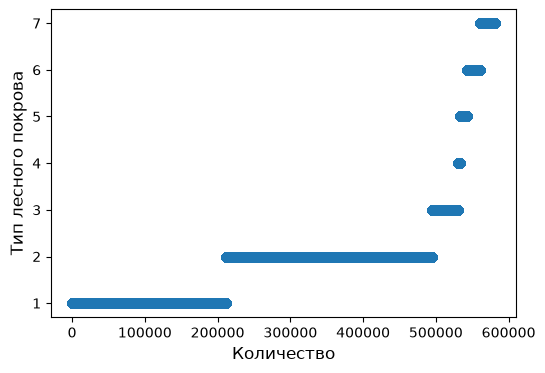

In [12]:
plt.figure(figsize=(6,4))
plt.scatter(range(df.shape[0]), np.sort(df.Тип_лесного_покрова.values))
plt.xlabel('Количество', fontsize=12)
plt.ylabel('Тип лесного покрова', fontsize=12)
plt.show()

## Анализ

В целевой переменной имеем 7 классов с ярко выраженным дисбалансом:

* Классы **1 и 2** доминируют и вместе занимают около 85% всех записей.
* Класс **4** — редчайший, менее 0.5% наблюдений.
* Между максимумом (класс 2) и минимумом (класс 4) разрыв более чем в 130 раз.

На практике это может привести к тому, что обученная модель будет отлично предсказывать классы, представленные в большинстве, но часто ошибаться на менее заметных. Исходя из этого можно сделать вывод о том, что необходимо каким либо образом, вероятнее всего средним, поднять уровень "маленьких" классов.

Ель/Пихра, Сосна скрученная, Сосна пондероза, Тополь/Ива, Осина, Дугласова пихта, Круммхольц

In [22]:
count = df.count()
total = df.shape[0]
for name, c in count.items():
    if c != total:
        print(f'имеет пустые={name}')

In [21]:
missing = df.isnull().sum()
missing

Высота_над_уровнем_моря         0
Азимут_склона                   0
Уклон_склона                    0
Расстояние_до_воды_гориз        0
Расстояние_до_воды_верт         0
Расстояние_до_дорог             0
Освещённость_9_утра             0
Освещённость_полдень            0
Освещённость_3_дня              0
Расстояние_до_пожарных_точек    0
Зона_дикой_природы_1            0
Зона_дикой_природы_2            0
Зона_дикой_природы_3            0
Зона_дикой_природы_4            0
Тип_почвы_1                     0
Тип_почвы_2                     0
Тип_почвы_3                     0
Тип_почвы_4                     0
Тип_почвы_5                     0
Тип_почвы_6                     0
Тип_почвы_7                     0
Тип_почвы_8                     0
Тип_почвы_9                     0
Тип_почвы_10                    0
Тип_почвы_11                    0
Тип_почвы_12                    0
Тип_почвы_13                    0
Тип_почвы_14                    0
Тип_почвы_15                    0
Тип_почвы_16  

## Анализ

Проверка показала, что во всех 55 столбцах пропуски отсутствуют. Так что применение методов заполнения пропусков не требуется, как для числовых, так и для категориальных столбцов. 

Сделанные выводы сходятся с данными, полученными из [репозитория машинного обучения Калифорнийского университета в Ирвайне](https://archive.ics.uci.edu/dataset/31/covertype), в котором впервые был опубликован рассматриваемый датасет. Также, стоит отметить, что типы данных столбцов, являющиеся полностью числовыми - это не ошибка загрузки, а условия оригинального набора данных, что также может быть найдено на указанном сайте.

In [25]:
print('min & max')
for col in numeric_cols:
    print(f'{col}: min={df[col].min()}, max={df[col].max()}')

min & max
Высота_над_уровнем_моря: min=1859, max=3858
Азимут_склона: min=0, max=360
Уклон_склона: min=0, max=66
Расстояние_до_воды_гориз: min=0, max=1397
Расстояние_до_воды_верт: min=-173, max=601
Расстояние_до_дорог: min=0, max=7117
Освещённость_9_утра: min=0, max=254
Освещённость_полдень: min=0, max=254
Освещённость_3_дня: min=0, max=254
Расстояние_до_пожарных_точек: min=0, max=7173


## Анализ

Выявим очевидные выбросы в числовых столбцах, оценив физическую осмысленность по экстремумам. Отмечу, что на данном этапе не утвержается, что выбросов в данных столбцах нет, так как рассматривается лишь логическая обусловленность значений. Точный анализ выбросов будет проделан далее в виде анализа квартилей:

* **Высота над уровнем моря**: лежит в диапазоне `[1859; 3858]`; отрицательных и нулевых значений нет; в целом экстремумы вполне могут соответствовать холмисто-гористой местности. Выбросов нет.
* **Азимут склона**: лежит в диапазоне `[0; 360]`; стандартный диапазон для угловых значений, но стоит учитывать что значения 0 и 360 фактически обозначают одно направление.
* **Уклон склон**: лежит в диапазоне `[0;66]`; ошибками могли стать значения больше 90 градусов - таковых нет.
* **Расстояние до воды горизонт**: лежит в `[0;1397]`; 0 здесь может объясняться тем, что участок расположен непосредственно около водоема.
* **Расстояние до воды верт** имеет отрицательные значения; здесь отрицательные значения могут объясняться нахождением в углублении, например, во впадине или котловине.
* **Расстояние до дорог**: `[0;7117]`; значения в целом согласуются с масштабами, однако возможно придется проводить масштабирование значений.
* **Освещеннность**: все три признака лежат в диапазоне 0-254; здесь проблем не наблюдается
* **РАсстояние до пожарных точек**: `[0;7173]`; аналогично расстоянию до дорог

Таким образом, все признаки имеют физически осмысленные диапазоны, соответствующие предметной области, однако требуется дополнительная проверка.

In [26]:
for c in numeric_cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = df[(df[c] < lower) | (df[c] > upper)]
    print(f'Target: {c}', f'Number of outliers: {len(outliers)}', f'Outliers: {outliers[c]}\n', sep='\n')

Target: Высота_над_уровнем_моря
Number of outliers: 15569
Outliers: 1820      2011
1824      2022
1825      2038
1827      2018
1837      2074
          ... 
573761    2274
573888    2271
574017    2270
574148    2270
574268    2274
Name: Высота_над_уровнем_моря, Length: 15569, dtype: int64

Target: Азимут_склона
Number of outliers: 0
Outliers: Series([], Name: Азимут_склона, dtype: int64)

Target: Уклон_склона
Number of outliers: 15316
Outliers: 124       33
167       33
504       33
716       32
884       40
          ..
580959    39
580960    38
580989    34
580990    35
580991    33
Name: Уклон_склона, Length: 15316, dtype: int64

Target: Расстояние_до_воды_гориз
Number of outliers: 14557
Outliers: 217       984
237       997
243       870
255       815
256       842
         ... 
554213    807
554214    830
554215    800
554407    811
554408    808
Name: Расстояние_до_воды_гориз, Length: 14557, dtype: int64

Target: Расстояние_до_воды_верт
Number of outliers: 31463
Outliers: 197  

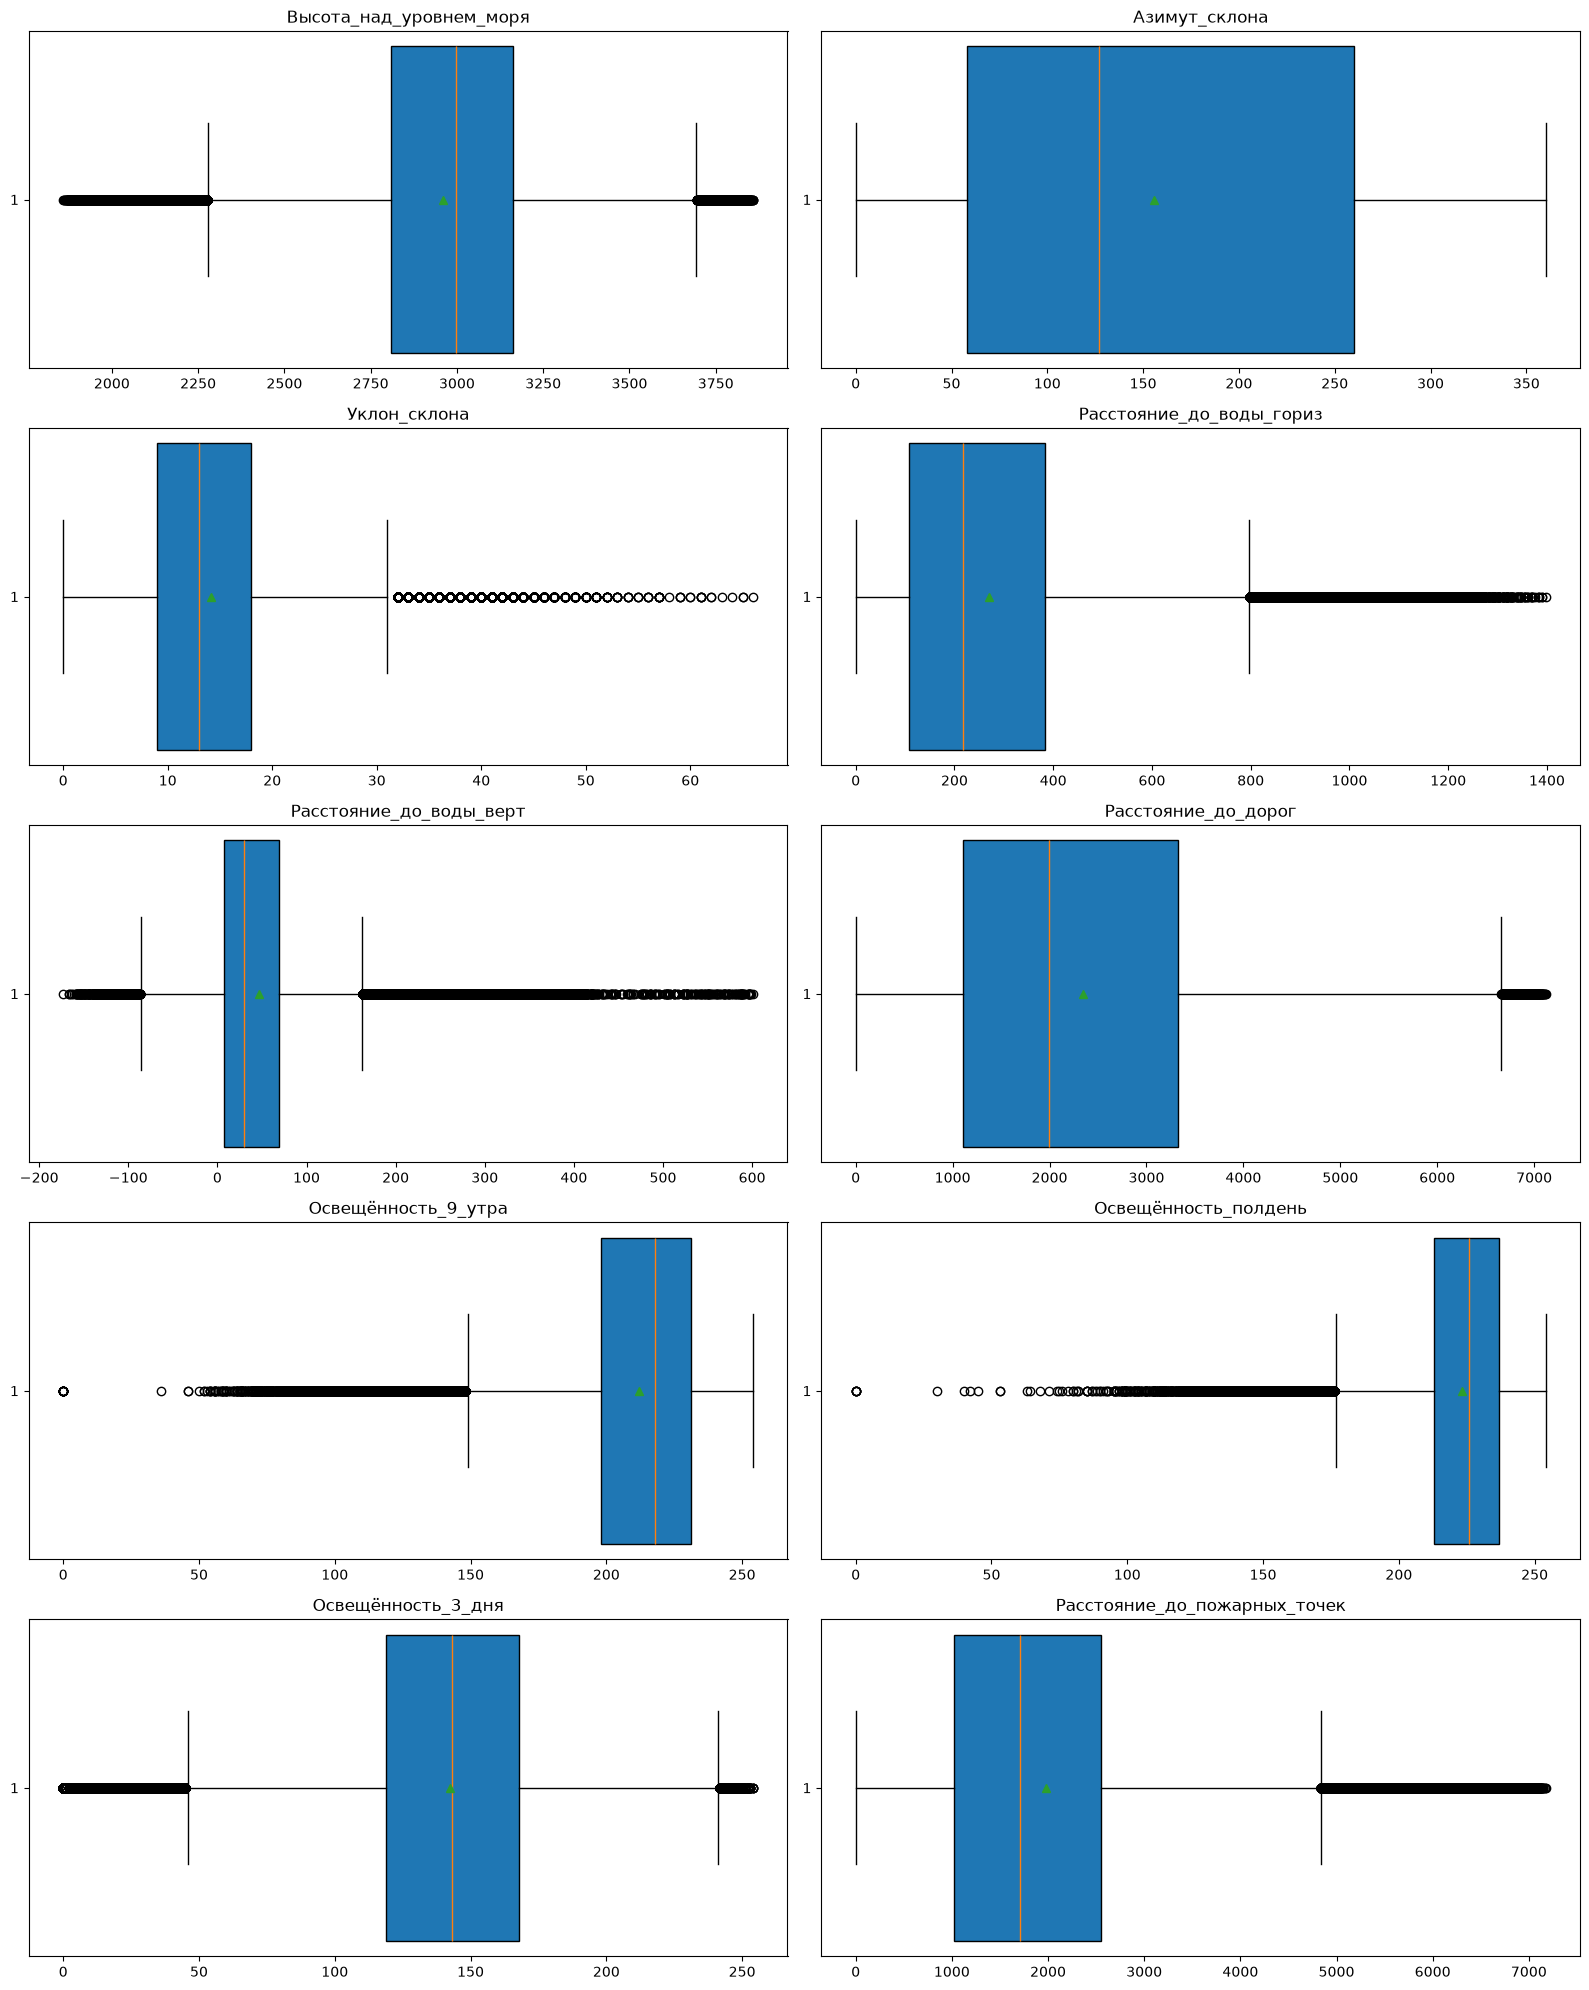

In [29]:
fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(df[col], widths=1.5, patch_artist=True, showmeans=True, orientation='horizontal')
    
    axes[i].set_title(f"{col}", fontsize=12)
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

## Анализ

Применение правила IQR, как и графическое изображение дало огромное количество выбросов. В перспективе, не считая пересечения, при удалении всех таких значений выборка может сократиться почти в половину. Здесь статистический критерий не говорит о плохой подготовке данных, так как их природа вполне обоснована. Для многих признаков отсекаются низкие и высокие значения, хотя они имеют место быть и не являются ошибками измерения

In [30]:
before = len(df)
dfc = df.drop_duplicates()
print(f'Удалено: {before - len(dfc)}')

Удалено: 0


In [31]:
print(f'Итоговый размер: {dfc.shape}')

Итоговый размер: (581012, 55)


## Анализ

Дубликатов нет, размер такой же?